# 1. Подготовка данных
Разбиение: 2021–2022 — расчёт порогов; 2023–2024 — выбор параметров; 2021–2024 — повторный расчёт порогов выбранных настроек; 2025–2026 YTD — итоговая оценка

In [1]:
from pathlib import Path
from itertools import product
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import seaborn as sns
from IPython.display import display

In [2]:
plt.rcParams.update({'figure.figsize': (14, 5), 'axes.grid': True, 'grid.alpha': 0.25})
pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', 120)
filename = 'deals_all_opt_2026-09-11__risk_uniform.csv'
data_path = Path('../data') / filename

In [3]:
calibration_end = pd.Timestamp('2022-12-31')
validation_start, validation_end = pd.Timestamp('2023-01-01'), pd.Timestamp('2024-12-31')
test_start = pd.Timestamp('2025-01-01')
q_grid = np.round(np.arange(0.90, 1.00, 0.01), 2)
k_grid = np.round(np.arange(0.50, 1.01, 0.10), 2)
recovery_grid = np.round(np.arange(0.50, 1.01, 0.10), 2)
reduced_grid = [0.0, 0.5]

In [4]:
trades = pd.read_csv(data_path, parse_dates=['entry_date', 'exit_date'])
required = ['strategy_name', 'entry_date', 'exit_date', 'profit_abs', 'profit_eq_pc', 'start_equity']

trades['trade_id'] = np.arange(len(trades))
trades = trades.sort_values(['entry_date', 'exit_date', 'trade_id'], kind='stable').reset_index(drop=True)
trades['entry_day'], trades['exit_day'] = trades['entry_date'].dt.normalize(), trades['exit_date'].dt.normalize()
strategies = pd.Index(sorted(trades['strategy_name'].unique()), name='strategy_name')
calendar = pd.date_range(trades['entry_day'].min(), trades['exit_day'].max(), freq='D', name='date')

test_end = trades['exit_day'].max()
cash_initial = float(trades['start_equity'].iloc[0])
first_entry = trades.groupby('strategy_name')['entry_day'].min().reindex(strategies)
day_positions = calendar.get_indexer(trades['entry_day'])
strategy_positions = strategies.get_indexer(trades['strategy_name'])
baseline_multiplier = np.ones(len(trades))
cash_values = trades['profit_abs'].to_numpy()
entry_days, exit_days = trades['entry_day'], trades['exit_day']

### 1.1. Виртуальные просадки и доступная история

Индивидуальные сигналы сохраняют прежнюю основу: накопленный `profit_eq_pc`, глубина в п.п. Денежные показатели портфеля рассчитываются по `profit_abs`. На день входа известны только закрытия до начала этого дня. Ниже строится полная история для удобства, но калибровка и симуляции ограничиваются своими датами.

In [5]:
virtual_daily = trades.groupby(['exit_day', 'strategy_name'])['profit_eq_pc'].sum().unstack('strategy_name').reindex(index=calendar, columns=strategies).fillna(0.0)
virtual_curve = virtual_daily.cumsum()
strategy_depth = virtual_curve.cummax().clip(lower=0) - virtual_curve
known_depth = strategy_depth.shift(1, fill_value=0.0).to_numpy()
active = pd.DataFrame(calendar.to_numpy()[:, None] >= first_entry.to_numpy()[None, :], index=calendar, columns=strategies)

In [6]:
def historical_depth(end):
    history = strategy_depth.loc[:end]
    return history.where(active.loc[history.index])

training_depth = historical_depth(calibration_end)
refit_depth = historical_depth(test_start - pd.Timedelta(days=1))
history_quality = pd.DataFrame({
    'First_entry': first_entry,
    'Calibration_days': training_depth.count(),
    'Calibration_closed_trades': trades.loc[exit_days <= calibration_end].groupby('strategy_name').size().reindex(strategies, fill_value=0)
})

def make_thresholds(history, metric, q=0.95, k=1.0):
    if metric == 'MDD':
        threshold = k * history.max()
    else:
        dar = history.quantile(q)
        threshold = dar if metric == 'DaR' else history.where(history.ge(dar, axis='columns')).mean()
    return threshold.reindex(strategies).to_numpy()

### 1.2. Правила временного ограничения

`recovery_fraction` — восстановленная доля **пороговой** глубины. При 0,5 возвращаемся на половине порога, при 1,0 — только при полном восстановлении к пику. Правило: ограничение при глубине ≥ A, возврат при глубине ≤ (1 − recovery_fraction) × A. Для нулевой границы используется численная точность 1e-10 п.п.

In [7]:
def individual_restrictions(threshold, start, end, recovery_fraction=0.5,
                            strict_restore=False, permanent=False):
    restricted = np.zeros((len(calendar), len(strategies)), dtype=bool)
    state = np.zeros(len(strategies), dtype=bool)
    restore_depth = (1 - recovery_fraction) * threshold
    for pos in np.flatnonzero((calendar >= start) & (calendar <= end)):
        depth = known_depth[pos]
        recovered = depth < restore_depth if strict_restore else depth <= restore_depth + 1e-10
        state = state | (depth >= threshold) if permanent else np.where(depth >= threshold, True, np.where(recovered, False, state))
        restricted[pos] = state
    return restricted

def entry_multipliers(restricted, reduced_multiplier):
    return np.where(restricted[day_positions, strategy_positions], reduced_multiplier, 1.0)

def individual_switches(restricted):
    return np.count_nonzero(restricted != np.vstack([np.zeros((1, len(strategies)), dtype=bool), restricted[:-1]]), axis=1)

def global_restrictions(depth, threshold, start, end):
    flags = np.zeros(len(calendar), dtype=bool)
    known = depth.shift(1, fill_value=0.0).to_numpy()
    state = False
    for pos in np.flatnonzero((calendar >= start) & (calendar <= end)):
        if known[pos] >= threshold:
            state = True
        elif known[pos] < 0.5 * threshold:
            state = False
        flags[pos] = state
    return flags

### 1.3. Единые денежные метрики

In [8]:
serious_dd_threshold_pct = 3.0
drawdown_ci_confidence = 0.95
drawdown_ci_resamples = 2000
drawdown_ci_block_days = 30
drawdown_ci_seed = 42

def drawdown_tail_ci(depth):
    values = depth.to_numpy(dtype=float)
    n = len(values)
    if n < 2 or not np.isfinite(values).all():
        return (np.nan,) * 4
    block_days = min(drawdown_ci_block_days, max(1, n // 4))
    rng = np.random.default_rng(drawdown_ci_seed)
    starts = rng.integers(0, n, size=(drawdown_ci_resamples, int(np.ceil(n / block_days))))
    indices = ((starts[:, :, None] + np.arange(block_days)) % n).reshape(drawdown_ci_resamples, -1)[:, :n]
    samples = values[indices]
    dar = np.quantile(samples, 0.95, axis=1)
    tail = samples >= dar[:, None]
    cdar = np.where(tail, samples, 0.0).sum(axis=1) / tail.sum(axis=1)
    alpha = (1 - drawdown_ci_confidence) / 2
    low, high = np.quantile(np.column_stack([dar, cdar]), [alpha, 1 - alpha], axis=0)
    return low[0], high[0], low[1], high[1]

In [9]:
def evaluate_variant(multiplier, start, end, switches=None, with_ci=False):
    start, end = pd.Timestamp(start), pd.Timestamp(end)
    pnl = pd.Series(cash_values * multiplier, index=trades.index)
    events = pnl.groupby(trades['exit_date']).sum().sort_index()
    daily = pnl.groupby(exit_days).sum().reindex(calendar, fill_value=0.0)
    full_balance = cash_initial + daily.cumsum()
    previous = full_balance.shift(1, fill_value=cash_initial)
    opening = cash_initial + events.loc[events.index < start].sum()
    selected_events = events.loc[(events.index >= start) & (events.index < end + pd.Timedelta(days=1))]
    equity = pd.concat([pd.Series([opening], index=[start]), opening + selected_events.cumsum()])
    peak = equity.cummax()
    event_depth_pct = (1 - equity / peak) * 100
    event_depth_cash = peak - equity
    balance = full_balance.loc[start:end]
    daily_peak = balance.cummax().clip(lower=opening)
    depth = ((1 - balance / daily_peak) * 100).clip(lower=0)
    cash_depth = (daily_peak - balance).clip(lower=0)
    underwater = cash_depth > 1e-9
    blocks = (~underwater).cumsum()
    serious = depth > serious_dd_threshold_pct + 1e-10
    returns = (daily / previous).loc[start:end]
    std = returns.std()
    downside = np.sqrt(np.mean(np.minimum(returns, 0) ** 2))
    final = equity.iloc[-1]
    net = final - opening
    days = len(balance)
    valid = opening > 0 and equity.gt(0).all()
    cagr = ((final / opening) ** (365.25 / days) - 1) * 100 if valid else np.nan
    mdd, max_loss = event_depth_pct.max(), event_depth_cash.max()
    dar, cash_dar = depth.quantile(0.95), cash_depth.quantile(0.95)
    entry_mask = entry_days.between(start, end).to_numpy()
    row = {
        'Start_USDT': opening, 'End_USDT': final, 'Net_PnL_USDT': net,
        'Return_pct': (final / opening - 1) * 100 if opening > 0 else np.nan,
        'CAGR_pct': cagr, 'MDD_pct': mdd, 'Max_drawdown_USDT': max_loss,
        'DaR95_pct': dar, 'CDaR95_pct': depth[depth >= dar].mean(),
        'DaR95_USDT': cash_dar, 'CDaR95_USDT': cash_depth[cash_depth >= cash_dar].mean(),
        'Calmar': cagr / mdd if mdd > 0 else np.nan,
        'RecoveryFactor': net / max_loss if max_loss > 0 else np.nan,
        'Sharpe': returns.mean() / std * np.sqrt(365) if valid and std > 0 else np.nan,
        'Sortino': returns.mean() / downside * np.sqrt(365) if valid and downside > 0 else np.nan,
        'Max_DD_duration_days': int(underwater.groupby(blocks).sum().max()),
        'Time_underwater_pct': underwater.mean() * 100,
        'Serious_DD_count': int(depth.groupby(blocks).max().gt(serious_dd_threshold_pct + 1e-10).sum()),
        'Serious_DD_days': int(serious.sum()),
        'Annualized_PnL_USDT': net / (days / 365.25),
        'Avg_multiplier': multiplier[entry_mask].mean(),
        'Trades_half_pct': np.mean(multiplier[entry_mask] == 0.5) * 100,
        'Trades_skipped_pct': np.mean(multiplier[entry_mask] == 0) * 100,
        'Switches': int(np.sum(switches[(calendar >= start) & (calendar <= end)])) if switches is not None else 0
    }
    if with_ci:
        for unit, values in [('pct', depth), ('USDT', cash_depth)]:
            lo_d, hi_d, lo_c, hi_c = drawdown_tail_ci(values)
            row.update({f'DaR95_{unit}_CI_low': lo_d, f'DaR95_{unit}_CI_high': hi_d,
                        f'CDaR95_{unit}_CI_low': lo_c, f'CDaR95_{unit}_CI_high': hi_c})
    return {'metrics': row, 'equity': equity, 'multiplier': multiplier}

def add_baseline_comparison(frame, baseline_pnl):
    result = frame.copy()
    result['PnL_delta_USDT'] = result['Net_PnL_USDT'] - baseline_pnl
    result['PnL_retained_pct'] = result['Net_PnL_USDT'] / baseline_pnl * 100 if baseline_pnl > 0 else np.nan
    return result

main_columns = ['Net_PnL_USDT', 'PnL_retained_pct', 'PnL_delta_USDT', 'Return_pct',
                'CAGR_pct', 'MDD_pct', 'DaR95_pct', 'CDaR95_pct', 'Calmar',
                'RecoveryFactor', 'Sharpe', 'Sortino', 'Max_DD_duration_days',
                'Time_underwater_pct', 'Serious_DD_count', 'Serious_DD_days',
                'Avg_multiplier', 'Trades_half_pct', 'Trades_skipped_pct', 'Switches']
ci_columns = ['DaR95_pct_CI_low', 'DaR95_pct_CI_high', 'CDaR95_pct_CI_low', 'CDaR95_pct_CI_high']
baseline_validation = evaluate_variant(baseline_multiplier, validation_start, validation_end)
baseline_test = evaluate_variant(baseline_multiplier, test_start, test_end, with_ci=True)

# 2. Исследования с подбором гиперпараметров

### 2.1. Сетка параметров и валидация 2023–2024

Итого 312 конфигураций. Порог каждой конфигурации рассчитывается только по 2021–2022. История 2025–2026 не участвует в вычислении её валидационных метрик.

k — коэффициент порога MDD
- Используется только для MDD: перебираем: 0,5; 0,6; 0,7; 0,8; 0,9; 1,0.
- Порог ограничения = k × исторический MDD стратегии

q — процентиль для DaR/CDaR
- Используется только для DaR и CDaR. Перебираем 0,90–0,99 с шагом 0,01.

Recovery_fraction — доля восстановления перед возвратом полного объёма 
- Перебираем: 0,5; 0,6; 0,7; 0,8; 0,9; 1,0.

Reduced_multiplier — размер новых позиций при ограничении 
- 0 — не открываем новые позиции;
- 0,5 — открываем их половинным объёмом.

In [10]:
config_rows = []
for metric in ['MDD', 'DaR', 'CDaR']:
    threshold_grid = k_grid if metric == 'MDD' else q_grid
    for value, recovery, reduced in product(threshold_grid, recovery_grid, reduced_grid):
        config_rows.append({'Metric': metric, 'q': np.nan if metric == 'MDD' else float(value),
                            'k': float(value) if metric == 'MDD' else 1.0,
                            'Recovery_fraction': float(recovery), 'Reduced_multiplier': reduced})
configurations = pd.DataFrame(config_rows).rename_axis('Config_ID')

threshold_cache = {}
validation_rows = []
for config_id, config in configurations.iterrows():
    key = (config.Metric, config.k if config.Metric == 'MDD' else config.q)
    if key not in threshold_cache:
        threshold_cache[key] = make_thresholds(training_depth, config.Metric,
                                               q=config.q if pd.notna(config.q) else 0.95, k=config.k)
    flags = individual_restrictions(threshold_cache[key], validation_start, validation_end, config.Recovery_fraction)
    multiplier = entry_multipliers(flags, config.Reduced_multiplier)
    run = evaluate_variant(multiplier, validation_start, validation_end, individual_switches(flags))
    validation_rows.append({'Config_ID': config_id, **run['metrics']})
grid_results = configurations.join(pd.DataFrame(validation_rows).set_index('Config_ID'))
grid_results = add_baseline_comparison(grid_results, baseline_validation['metrics']['Net_PnL_USDT'])
b = baseline_validation['metrics']

display(add_baseline_comparison(pd.DataFrame([b], index=['Baseline: 2023–2024']), b['Net_PnL_USDT'])[main_columns])

,Net_PnL_USDT,PnL_retained_pct,PnL_delta_USDT,Return_pct,CAGR_pct,MDD_pct,DaR95_pct,CDaR95_pct,Calmar,RecoveryFactor,Sharpe,Sortino,Max_DD_duration_days,Time_underwater_pct,Serious_DD_count,Serious_DD_days,Avg_multiplier,Trades_half_pct,Trades_skipped_pct,Switches
Baseline: 2023–2024,171574.336973,100.0,0.0,447.988829,133.955465,7.639132,5.056897,5.846112,17.535429,26.979632,4.082852,16.689163,60,78.932969,10,147,1.0,0.0,0.0,0


In [11]:
grid_results['PnL_ge_baseline'] = grid_results.Net_PnL_USDT >= b['Net_PnL_USDT'] - 1e-8
grid_results['MDD_lt_baseline'] = grid_results.MDD_pct < b['MDD_pct'] - 1e-10
grid_results['Sharpe_ge_baseline'] = grid_results.Sharpe >= b['Sharpe']
grid_results['Goal_PnL_MDD'] = grid_results.PnL_ge_baseline & grid_results.MDD_lt_baseline
grid_results['Goal_all'] = grid_results.Goal_PnL_MDD & grid_results.Sharpe_ge_baseline
parameter_columns = list(configurations.columns)
display(grid_results.sort_values(['Goal_all', 'Goal_PnL_MDD', 'Calmar', 'Net_PnL_USDT'], ascending=False)[
    parameter_columns + main_columns + ['Goal_PnL_MDD', 'Goal_all']].head(30).round(3))

,Metric,q,k,Recovery_fraction,Reduced_multiplier,Net_PnL_USDT,PnL_retained_pct,PnL_delta_USDT,Return_pct,CAGR_pct,MDD_pct,DaR95_pct,CDaR95_pct,Calmar,RecoveryFactor,Sharpe,Sortino,Max_DD_duration_days,Time_underwater_pct,Serious_DD_count,Serious_DD_days,Avg_multiplier,Trades_half_pct,Trades_skipped_pct,Switches,Goal_PnL_MDD,Goal_all
Config_ID,,,,,,,,,,,,,,,,,,,,,,,,,,,
263,CDaR,0.95,1.0,1.0,0.5,150785.301,87.883,-20789.036,393.708,122.074,6.462,4.821,5.514,18.891,24.549,4.036,15.970,60,79.070,10,144,0.897,20.698,0.0,381,False,False
179,DaR,0.98,1.0,1.0,0.5,150979.920,87.997,-20594.417,394.216,122.188,6.469,4.844,5.526,18.889,24.591,4.033,15.951,60,79.070,10,144,0.898,20.453,0.0,375,False,False
167,DaR,0.97,1.0,1.0,0.5,150598.005,87.774,-20976.332,393.219,121.964,6.479,4.822,5.530,18.826,24.518,4.036,15.985,60,79.343,10,145,0.889,22.264,0.0,410,False,False
47,MDD,NaN,0.8,1.0,0.5,149132.607,86.920,-22441.730,389.392,121.102,6.488,4.799,5.519,18.665,24.334,4.016,15.932,60,79.480,10,140,0.886,22.861,0.0,436,False,False
251,CDaR,0.94,1.0,1.0,0.5,150531.510,87.735,-21042.827,393.045,121.925,6.533,4.831,5.573,18.663,24.507,4.030,15.936,60,79.343,10,146,0.892,21.686,0.0,394,False,False
275,CDaR,0.96,1.0,1.0,0.5,151177.950,88.112,-20396.387,394.733,122.304,6.571,4.879,5.551,18.612,24.613,4.022,15.914,60,79.207,10,146,0.902,19.583,0.0,371,False,False
215,CDaR,0.91,1.0,1.0,0.5,148730.376,86.686,-22843.961,388.342,120.865,6.498,4.805,5.538,18.600,24.348,4.022,15.972,60,79.207,11,146,0.878,24.404,0.0,447,False,False
239,CDaR,0.93,1.0,1.0,0.5,149888.748,87.361,-21685.588,391.367,121.547,6.540,4.834,5.573,18.587,24.403,4.017,15.903,60,79.343,11,146,0.887,22.542,0.0,417,False,False
203,CDaR,0.90,1.0,1.0,0.5,147233.609,85.813,-24340.728,384.434,119.980,6.475,4.773,5.551,18.531,24.181,4.005,15.876,60,79.207,11,147,0.875,25.086,0.0,470,False,False


### 2.2. Поверхности результатов валидации

На графиках — Calmar валидации при разных порогах и долях восстановления. Выбор настроек выполняется по заранее описанным правилам ниже, а не по внешнему виду итоговых графиков 2025–2026.

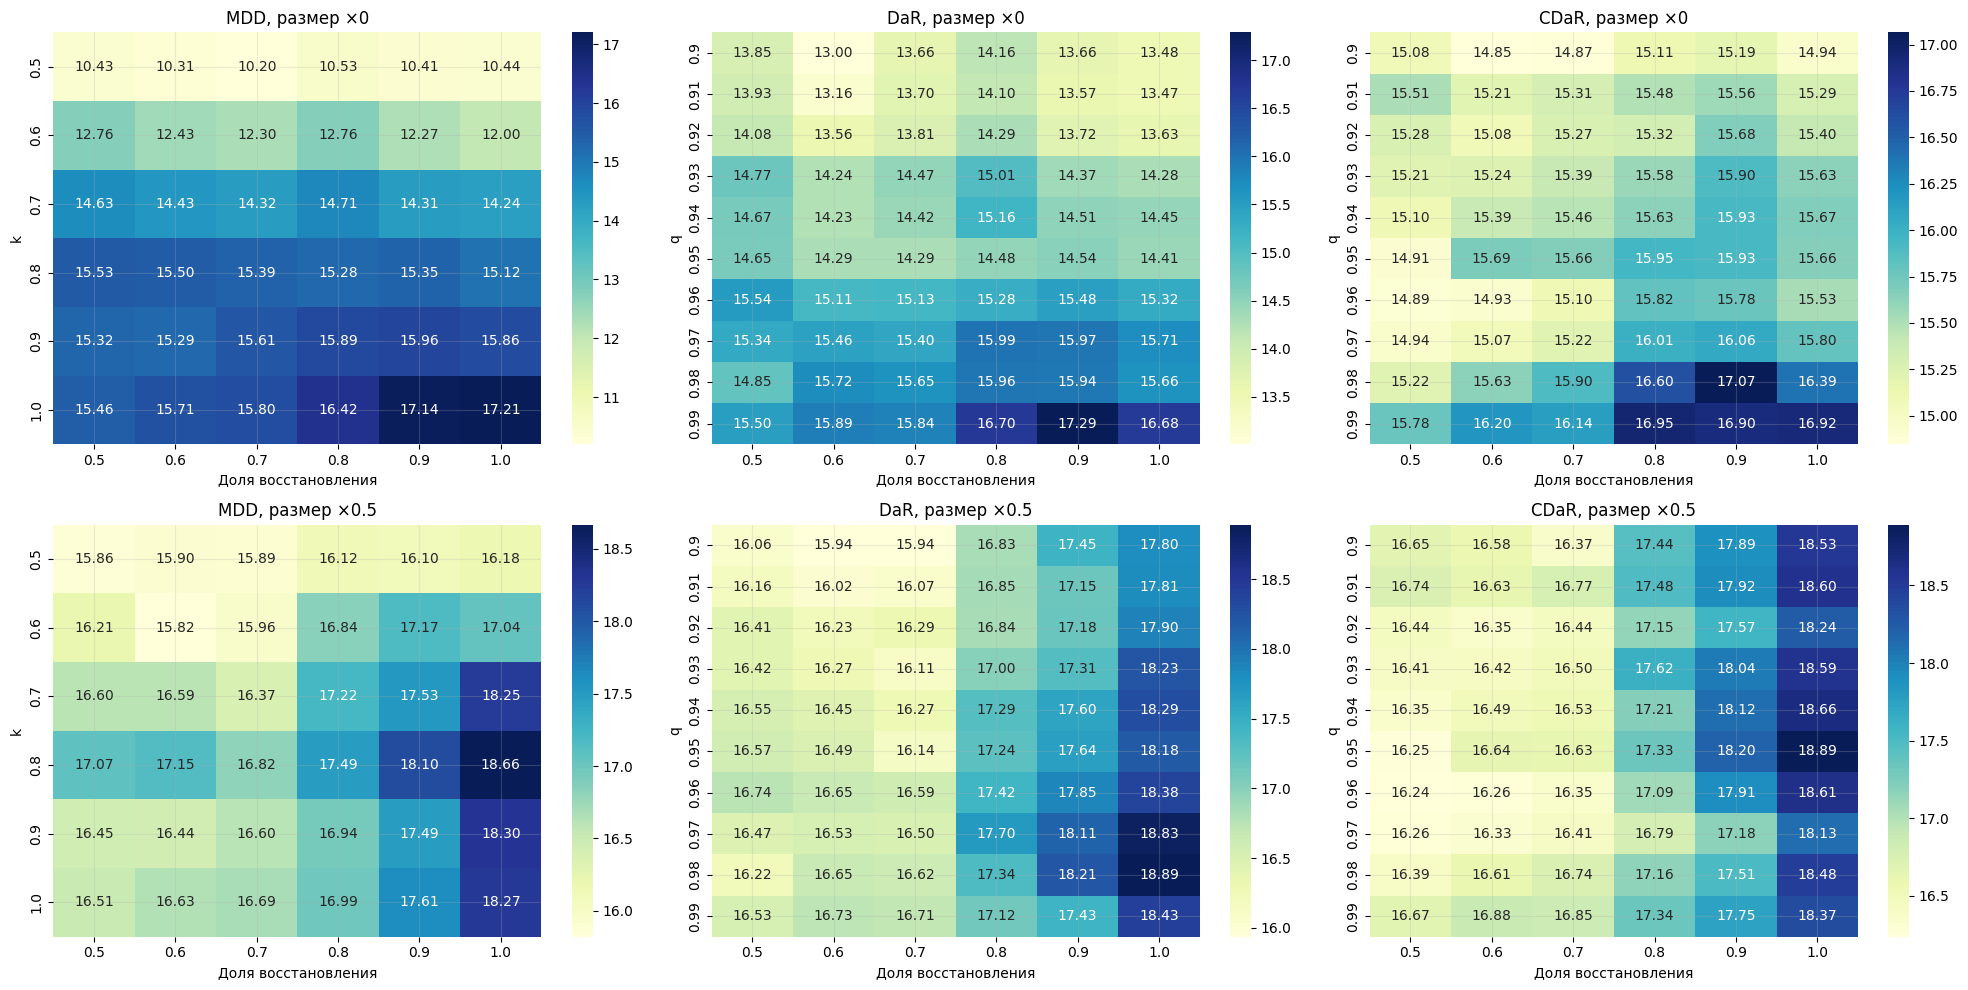

In [12]:
fig, axes = plt.subplots(2, 3, figsize=(20, 10))
for col, metric in enumerate(['MDD', 'DaR', 'CDaR']):
    for row, reduced in enumerate(reduced_grid):
        subset = grid_results.loc[(grid_results.Metric == metric) & (grid_results.Reduced_multiplier == reduced)]
        key = 'k' if metric == 'MDD' else 'q'
        surface = subset.pivot(index=key, columns='Recovery_fraction', values='Calmar')
        sns.heatmap(surface, annot=True, fmt='.2f', cmap='YlGnBu', ax=axes[row, col])
        axes[row, col].set(title=f'{metric}, размер ×{reduced:g}', xlabel='Доля восстановления', ylabel=key)
plt.tight_layout()
plt.show()

### 2.3. Выбор настроек до итогового периода

Выбираем три ориентира по 2023–2024:

- **Calmar:** сначала рассматриваем настройки с PnL ≥ Baseline, меньшей MDD и Sharpe ≥ Baseline. Если таких нет — с выполнением только первых двух условий; если нет и их — показываем лучший Calmar без заявления о выполнении цели.
- **PnL:** максимальный денежный PnL на валидации.
- **MDD:** минимальная MDD среди настроек с PnL ≥ Baseline. Если таких нет — минимальная MDD всей сетки, с явным указанием потери прибыли.

In [14]:
eligible_calmar = grid_results.loc[grid_results.Goal_all]
if eligible_calmar.empty:
    eligible_calmar = grid_results.loc[grid_results.Goal_PnL_MDD]
if eligible_calmar.empty:
    eligible_calmar = grid_results

risk_pool = grid_results.loc[grid_results.PnL_ge_baseline]
if risk_pool.empty:
    risk_pool = grid_results

chosen = {
    'Calmar': int(eligible_calmar.sort_values(['Calmar', 'Net_PnL_USDT', 'MDD_pct'],ascending=[False, False, True]).index[0]),
    'PnL': int(grid_results.sort_values(['Net_PnL_USDT', 'Calmar'], ascending=False).index[0]),
    'MDD': int(risk_pool.sort_values(['MDD_pct', 'Net_PnL_USDT'], ascending=[True, False]).index[0])
}

selected_configurations = grid_results.loc[list(dict.fromkeys(chosen.values()))].copy()
selected_configurations.insert(0, 'Chosen_by',[', '.join(rule for rule, value in chosen.items() if value == idx) for idx in selected_configurations.index])
display(selected_configurations[['Chosen_by'] + parameter_columns + main_columns].round(3))

,Chosen_by,Metric,q,k,Recovery_fraction,Reduced_multiplier,Net_PnL_USDT,PnL_retained_pct,PnL_delta_USDT,Return_pct,CAGR_pct,MDD_pct,DaR95_pct,CDaR95_pct,Calmar,RecoveryFactor,Sharpe,Sortino,Max_DD_duration_days,Time_underwater_pct,Serious_DD_count,Serious_DD_days,Avg_multiplier,Trades_half_pct,Trades_skipped_pct,Switches
Config_ID,,,,,,,,,,,,,,,,,,,,,,,,,,
263,Calmar,CDaR,0.95,1.0,1.0,0.5,150785.301,87.883,-20789.036,393.708,122.074,6.462,4.821,5.514,18.891,24.549,4.036,15.970,60,79.070,10,144,0.897,20.698,0.0,381
61,PnL,MDD,NaN,1.0,0.5,0.5,160169.073,93.353,-11405.264,418.209,127.514,7.725,5.166,6.011,16.507,25.628,4.024,15.942,60,79.207,10,155,0.959,8.108,0.0,310
83,MDD,DaR,0.90,1.0,1.0,0.5,138405.086,80.668,-33169.251,361.382,114.686,6.444,4.773,5.476,17.798,23.874,3.964,15.501,60,80.164,10,140,0.832,33.551,0.0,710


### 2.4. Пересчёт порогов по 2021–2024 и итоговая оценка 2025–2026

Гиперпараметры уже зафиксированы. Порог каждого алгоритма повторно оценивается на 2021–2024. Новый контроль включается с 01.01.2025; до этого новые варианты совпадают с Baseline. Доля восстановления и действия сохраняются выбранными на валидации.

In [15]:
test_runs = {'Baseline': baseline_test}
refit_threshold_rows = []
for config_id, config in selected_configurations.iterrows():
    thresholds = make_thresholds(refit_depth, config.Metric,
                                 q=config.q if pd.notna(config.q) else 0.95, k=config.k)
    flags = individual_restrictions(thresholds, test_start, test_end, config.Recovery_fraction)
    multiplier = entry_multipliers(flags, config.Reduced_multiplier)
    label = f'Grid {config.Chosen_by} [#{config_id}]'
    test_runs[label] = evaluate_variant(multiplier, test_start, test_end, individual_switches(flags), with_ci=True)
    refit_threshold_rows.append(pd.Series(thresholds, index=strategies, name=label))
refitted_thresholds = pd.concat(refit_threshold_rows, axis=1)

### 2.5. Ориентиры из прежних гипотез

In [ ]:
benchmark_runs = {'Baseline': baseline_test}
fixed_flags = individual_restrictions(np.full(len(strategies), 0.5), calendar[0], test_end,
                                     recovery_fraction=0.5, strict_restore=True)
benchmark_runs['Fixed DD 1→0.5'] = evaluate_variant(entry_multipliers(fixed_flags, 0.5), test_start, test_end,
                                                  individual_switches(fixed_flags))
base_daily = trades.groupby('exit_day')['profit_abs'].sum().reindex(calendar, fill_value=0.0)
base_balance = cash_initial + base_daily.cumsum()
portfolio_depth = (1 - base_balance / base_balance.cummax().clip(lower=cash_initial)) * 100
portfolio_history = portfolio_depth.loc[portfolio_depth.index < test_start]
portfolio_dar = portfolio_history.quantile(0.95)
portfolio_thresholds = {'MDD': portfolio_history.max(), 'DaR': portfolio_dar,
                        'CDaR': portfolio_history[portfolio_history >= portfolio_dar].mean()}

for metric in ['MDD', 'DaR', 'CDaR']:
    thresholds = make_thresholds(refit_depth, metric)
    flags = individual_restrictions(thresholds, test_start, test_end, 0.5, strict_restore=True)
    permanent = individual_restrictions(thresholds, test_start, test_end, permanent=True)
    for reduced in [0.5, 0.0]:
        label = f'Individual {metric} 1→{reduced:g}'
        benchmark_runs[label] = evaluate_variant(entry_multipliers(flags, reduced), test_start, test_end,
                                                 individual_switches(flags))
    benchmark_runs[f'Individual {metric} permanent'] = evaluate_variant(
        entry_multipliers(permanent, 0.0), test_start, test_end, individual_switches(permanent))
    p_flags = global_restrictions(portfolio_depth, portfolio_thresholds[metric], test_start, test_end)
    p_changes = np.r_[False, p_flags[1:] != p_flags[:-1]].astype(int)
    for reduced in [0.0, 0.5]:
        p_mode = np.where(p_flags, reduced, 1.0)
        benchmark_runs[f'Portfolio {metric} 1→{reduced:g}'] = evaluate_variant(
            p_mode[day_positions], test_start, test_end, p_changes)
        joint_mode = (~flags).astype(float) * p_mode[:, None]
        joint_multiplier = joint_mode[day_positions, strategy_positions]
        joint_changes = np.count_nonzero(joint_mode != np.vstack([np.ones((1, len(strategies))), joint_mode[:-1]]), axis=1)
        benchmark_runs[f'Joint {metric} 0/{reduced:g}'] = evaluate_variant(
            joint_multiplier, test_start, test_end, joint_changes)

benchmark_metrics = pd.DataFrame({name: run['metrics'] for name, run in benchmark_runs.items()}).T.rename_axis('Method')
benchmark_metrics = add_baseline_comparison(benchmark_metrics, baseline_test['metrics']['Net_PnL_USDT'])
nonbaseline = benchmark_metrics.drop(index='Baseline')
reference_names = {
    'Максимальный PnL прежних гипотез': nonbaseline.sort_values(['Net_PnL_USDT', 'MDD_pct'], ascending=[False, True]).index[0],
    'Минимальная MDD прежних гипотез': nonbaseline.sort_values(['MDD_pct', 'Net_PnL_USDT'], ascending=[True, False]).index[0]
}
display(benchmark_metrics[main_columns].sort_values('Net_PnL_USDT', ascending=False).round(3))
display(pd.Series(reference_names, name='Reference_method').to_frame())
for name in dict.fromkeys(reference_names.values()):
    run = benchmark_runs[name]
    test_runs[f'Reference: {name}'] = evaluate_variant(run['multiplier'], test_start, test_end, with_ci=True)
    test_runs[f'Reference: {name}']['metrics']['Switches'] = run['metrics']['Switches']

### 2.6. Единая итоговая таблица

Здесь сравниваются Baseline, выбранные по валидации настройки и ориентиры прежних гипотез. `PnL_retained_pct` — отношение денежного PnL к Baseline, а `Return_pct` — доходность на начальный баланс периода. Все показатели доходности и риска оцениваются по денежной кривой общего портфеля.

In [22]:
test_metrics = pd.DataFrame({name: run['metrics'] for name, run in test_runs.items()}).T.rename_axis('Method')
test_metrics = add_baseline_comparison(test_metrics, baseline_test['metrics']['Net_PnL_USDT'])

columns = list(dict.fromkeys(main_columns + ['DaR95_pct', 'CDaR95_pct'] + ci_columns))
display(test_metrics[columns].round(3))

,Net_PnL_USDT,PnL_retained_pct,PnL_delta_USDT,Return_pct,CAGR_pct,MDD_pct,DaR95_pct,CDaR95_pct,Calmar,RecoveryFactor,Sharpe,Sortino,Max_DD_duration_days,Time_underwater_pct,Serious_DD_count,Serious_DD_days,Avg_multiplier,Trades_half_pct,Trades_skipped_pct,Switches,DaR95_pct_CI_low,DaR95_pct_CI_high,CDaR95_pct_CI_low,CDaR95_pct_CI_high
Method,,,,,,,,,,,,,,,,,,,,,,,,
Baseline,268927.973,100.000,0.000,128.138,62.690,25.659,20.411,22.580,2.443,1.882,2.440,8.669,215.0,84.976,9.0,286.0,1.000,0.000,0.0,0.0,13.957,23.018,18.197,24.184
Grid Calmar [#263],266812.083,99.213,-2115.890,127.130,62.265,18.676,15.671,16.831,3.334,2.643,2.609,9.683,215.0,84.814,9.0,282.0,0.885,22.928,0.0,140.0,11.783,17.055,14.124,17.748
Grid PnL [#61],264544.343,98.370,-4383.630,126.050,61.809,20.880,17.592,18.975,2.960,2.299,2.554,9.336,215.0,84.976,9.0,285.0,0.916,16.730,0.0,142.0,13.898,19.193,16.107,19.919
Grid MDD [#83],243059.204,90.381,-25868.769,115.812,57.444,17.658,14.591,15.818,3.253,2.716,2.527,9.311,215.0,85.784,9.0,285.0,0.816,36.896,0.0,352.0,10.771,16.032,13.181,16.695


### 2.7. Доходность и просадка: 2025–2026

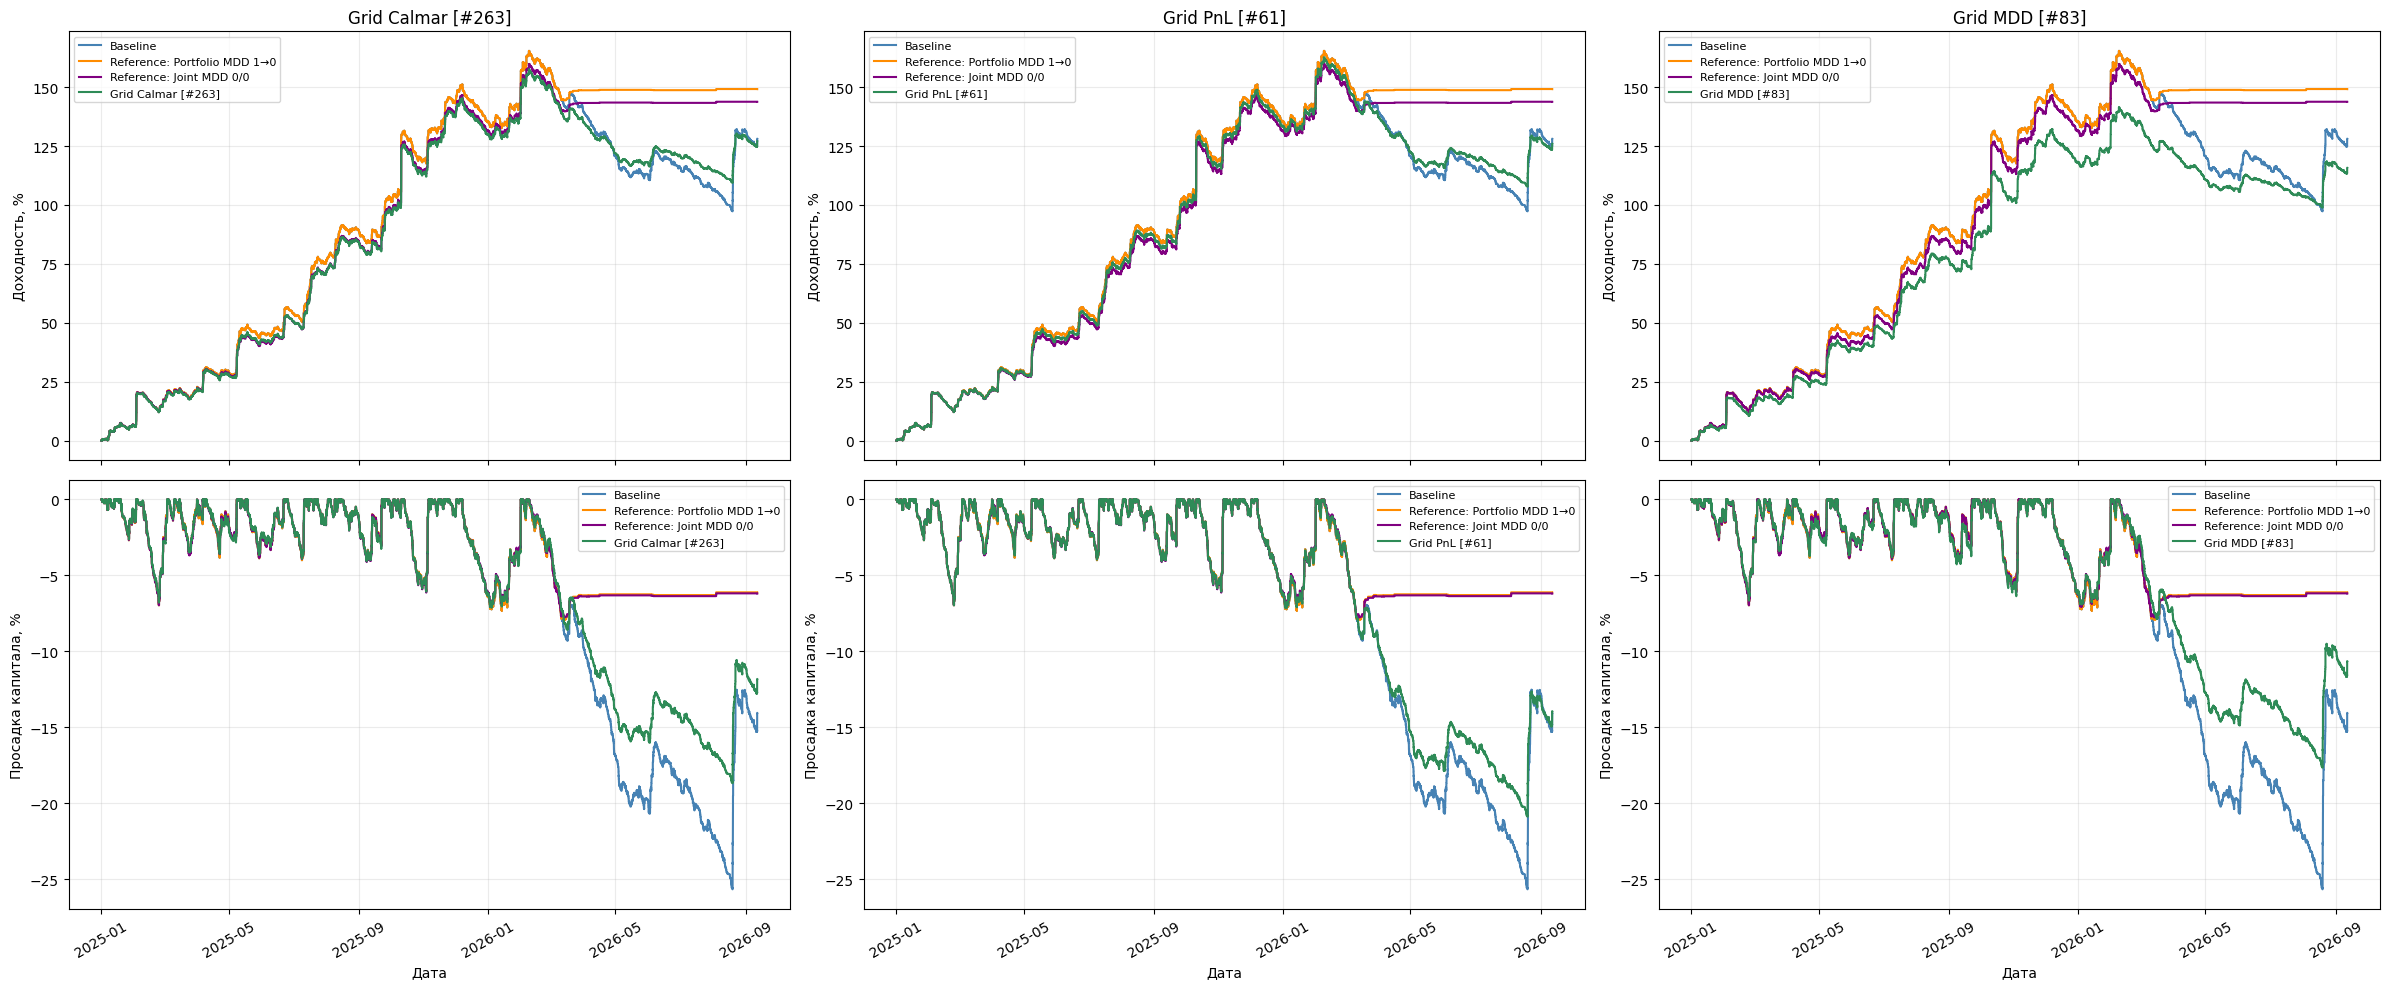

In [13]:
reference_labels = [name for name in test_runs if name.startswith('Reference: ')]
fig, axes = plt.subplots(2, len(selected_test_names), figsize=(8 * len(selected_test_names), 10), sharex=True, squeeze=False)
colors = ['steelblue', 'darkorange', 'purple', 'seagreen']
for col, candidate_name in enumerate(selected_test_names):
    labels = ['Baseline'] + reference_labels + [candidate_name]
    for name, color in zip(labels, colors):
        run = test_runs[name]
        equity = run['equity']
        returns = (equity / run['metrics']['Start_USDT'] - 1) * 100
        drawdown = (equity / equity.cummax() - 1) * 100
        axes[0, col].step(equity.index, returns, where='post', label=name, color=color)
        axes[1, col].step(equity.index, drawdown, where='post', label=name, color=color)
    axes[0, col].set(title=candidate_name, ylabel='Доходность, %')
    axes[1, col].set(ylabel='Просадка капитала, %', xlabel='Дата')
    axes[1, col].xaxis.set_major_locator(mdates.MonthLocator(interval=4))
    axes[1, col].xaxis.set_major_formatter(mdates.DateFormatter('%Y-%m'))
    axes[1, col].tick_params(axis='x', rotation=30)
    for ax in axes[:, col]:
        ax.legend(fontsize=8)
plt.tight_layout()
plt.show()